Créer une première session Spark

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
import pandas as pd
import matplotlib.pyplot as plt

spark = (
    SparkSession.builder
    .master("local[2]")
    .appName("TP4-Retail-Intelligence")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

print("Spark :", spark.version)
print("Pandas :", pd.__version__)
print("Jupyter TP4 prêt !")


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/19 14:14:00 WARN Utils: Your hostname, DESKTOP-38E0JSC, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/19 14:14:00 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/honi/environnements/retail-tp3/lib/python3.14/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/11/19 14:14:05 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark : 4.3.0
Pandas : 3.1.1
Jupyter TP4 prêt !


Lire les fichiers Parquet

In [2]:

BASE = "hdfs://localhost:9000/retail-lake"

ventes = spark.read.parquet(
    f"{BASE}/silver/uc06_store_sales"
)

gold_magasins = spark.read.parquet(
    f"{BASE}/gold/uc06_finance_magasins"
)

gold_articles = spark.read.parquet(
    f"{BASE}/gold/uc06_finance_articles"
)

print("===== VENTES SILVER =====")
print("Nombre de lignes :", ventes.count())
ventes.printSchema()

print("\n===== GOLD MAGASINS =====")
gold_magasins.show(5, truncate=False)

print("\n===== GOLD ARTICLES =====")
gold_articles.show(5, truncate=False)


===== VENTES SILVER =====
Nombre de lignes : 667579
root
 |-- _c0: string (nullable = true)
 |-- _c1: string (nullable = true)
 |-- _c2: string (nullable = true)
 |-- _c3: string (nullable = true)
 |-- _c4: string (nullable = true)
 |-- _c5: string (nullable = true)
 |-- _c6: string (nullable = true)
 |-- _c7: string (nullable = true)
 |-- _c8: string (nullable = true)
 |-- _c9: string (nullable = true)
 |-- _c10: string (nullable = true)
 |-- _c11: string (nullable = true)
 |-- _c12: string (nullable = true)
 |-- _c13: string (nullable = true)
 |-- _c14: string (nullable = true)
 |-- _c15: string (nullable = true)
 |-- _c16: string (nullable = true)
 |-- _c17: string (nullable = true)
 |-- _c18: string (nullable = true)
 |-- _c19: string (nullable = true)
 |-- _c20: string (nullable = true)
 |-- _c21: string (nullable = true)
 |-- _c22: string (nullable = true)


===== GOLD MAGASINS =====


+----------+-------------+---------------+------------+-----------+--------------+
|magasin_id|nombre_lignes|quantite_totale|total_ventes|total_net  |total_benefice|
+----------+-------------+---------------+------------+-----------+--------------+
|7         |57589        |2915053        |109714870.06|98950137.76|-47643702.48  |
|11        |55473        |2790631        |106007960.27|95607843.48|-45346473.98  |
|3         |55397        |2800824        |106544945.30|96063990.59|-45725385.12  |
|8         |55737        |2821869        |107232486.60|96578622.89|-45837269.98  |
|0         |56018        |2830581        |107232320.14|96727851.94|-46086598.19  |
+----------+-------------+---------------+------------+-----------+--------------+
only showing top 5 rows

===== GOLD ARTICLES =====
+----------+-------------+---------------+------------+----------+--------------+
|article_id|nombre_lignes|quantite_totale|total_ventes|total_net |total_benefice|
+----------+-------------+------------

Verification des donnée, schema, granularité

In [4]:

# Chemins des données du TP3
BASE = "hdfs://localhost:9000/retail-lake"

# Données Silver
silver_ventes = spark.read.parquet(
    f"{BASE}/silver/uc06_store_sales"
)

silver_articles = spark.read.parquet(
    f"{BASE}/silver/uc06_item"
)

silver_magasins = spark.read.parquet(
    f"{BASE}/silver/uc06_store"
)

# Données Gold
gold_magasins = spark.read.parquet(
    f"{BASE}/gold/uc06_finance_magasins"
)

gold_articles = spark.read.parquet(
    f"{BASE}/gold/uc06_finance_articles"
)

print("===== DONNÉES CHARGÉES =====")

for nom, df in [
    ("Silver ventes", silver_ventes),
    ("Silver articles", silver_articles),
    ("Silver magasins", silver_magasins),
    ("Gold magasins", gold_magasins),
    ("Gold articles", gold_articles)
]:
    print(f"{nom} : {df.count()} lignes, {len(df.columns)} colonnes")


===== DONNÉES CHARGÉES =====


Silver ventes : 667579 lignes, 23 colonnes


Silver articles : 17820 lignes, 22 colonnes
Silver magasins : 12 lignes, 29 colonnes
Gold magasins : 12 lignes, 6 colonnes
Gold articles : 17820 lignes, 6 colonnes


In [5]:

print("===== SCHÉMA SILVER VENTES =====")
silver_ventes.printSchema()

print("\n===== SCHÉMA GOLD MAGASINS =====")
gold_magasins.printSchema()

print("\n===== DONNÉES GOLD MAGASINS =====")
gold_magasins.orderBy("magasin_id").show(
    12, truncate=False
)

print("\n===== QUALITÉ DES CLÉS =====")

print(
    "Magasins distincts :",
    gold_magasins.select("magasin_id").distinct().count()
)

print(
    "Articles distincts :",
    gold_articles.select("article_id").distinct().count()
)


===== SCHÉMA SILVER VENTES =====
root
 |-- _c0: string (nullable = true)
 |-- _c1: string (nullable = true)
 |-- _c2: string (nullable = true)
 |-- _c3: string (nullable = true)
 |-- _c4: string (nullable = true)
 |-- _c5: string (nullable = true)
 |-- _c6: string (nullable = true)
 |-- _c7: string (nullable = true)
 |-- _c8: string (nullable = true)
 |-- _c9: string (nullable = true)
 |-- _c10: string (nullable = true)
 |-- _c11: string (nullable = true)
 |-- _c12: string (nullable = true)
 |-- _c13: string (nullable = true)
 |-- _c14: string (nullable = true)
 |-- _c15: string (nullable = true)
 |-- _c16: string (nullable = true)
 |-- _c17: string (nullable = true)
 |-- _c18: string (nullable = true)
 |-- _c19: string (nullable = true)
 |-- _c20: string (nullable = true)
 |-- _c21: string (nullable = true)
 |-- _c22: string (nullable = true)


===== SCHÉMA GOLD MAGASINS =====
root
 |-- magasin_id: string (nullable = true)
 |-- nombre_lignes: long (nullable = true)
 |-- quantite_total

+----------+-------------+---------------+------------+-----------+--------------+
|magasin_id|nombre_lignes|quantite_totale|total_ventes|total_net  |total_benefice|
+----------+-------------+---------------+------------+-----------+--------------+
|0         |56018        |2830581        |107232320.14|96727851.94|-46086598.19  |
|1         |55676        |2817524        |106406449.75|95929844.66|-46172561.01  |
|10        |55109        |2785773        |104668943.12|94263977.55|-46326552.26  |
|11        |55473        |2790631        |106007960.27|95607843.48|-45346473.98  |
|2         |54633        |2760007        |104610803.14|94040402.78|-45062627.38  |
|3         |55397        |2800824        |106544945.30|96063990.59|-45725385.12  |
|4         |56211        |2832572        |107292630.20|96770105.59|-46245313.52  |
|5         |55122        |2789703        |104691960.79|94097279.37|-46285140.04  |
|6         |54574        |2780253        |105525800.61|94751173.08|-45805948.18  |
|7  

In [6]:

from pyspark.sql import functions as F

print("===== CONTROLE QUALITE GOLD =====")

# 1. Valeurs nulles dans les indicateurs
colonnes_kpi = [
    "nombre_lignes",
    "quantite_totale",
    "total_ventes",
    "total_net",
    "total_benefice"
]

for colonne in colonnes_kpi:
    nb_null = gold_magasins.filter(
        F.col(colonne).isNull()
    ).count()

    print(f"{colonne} : {nb_null} NULL")

# 2. Cohérence entre les données Silver et Gold
total_silver = silver_ventes.count()

total_gold = gold_magasins.agg(
    F.sum("nombre_lignes")
).first()[0]

print("\n===== CONSERVATION DES LIGNES =====")
print("Silver :", total_silver)
print("Gold :", total_gold)

assert total_silver == total_gold

print("Contrôle réussi : toutes les lignes sont conservées.")


===== CONTROLE QUALITE GOLD =====
nombre_lignes : 0 NULL
quantite_totale : 0 NULL
total_ventes : 0 NULL
total_net : 0 NULL
total_benefice : 0 NULL

===== CONSERVATION DES LIGNES =====
Silver : 667579
Gold : 667579
Contrôle réussi : toutes les lignes sont conservées.



## Définition et calcul des KPI

### Objectif
Calculer les principaux indicateurs d'activité commerciale
à partir des données Gold produites lors du TP3.

### Source des données
- Table : `gold/uc06_finance_magasins`
- Format : Parquet
- Stockage : Hadoop HDFS
- Granularité : un enregistrement agrégé par magasin
- Périmètre : 12 magasins

### Indicateurs retenus

| KPI | Formule | Unité |
|---|---|---|
| Nombre de lignes de ventes | SUM(nombre_lignes) | Lignes |
| Quantité totale | SUM(quantite_totale) | Unités |
| Montant des ventes | SUM(total_ventes) | Unité monétaire à confirmer |
| Montant net | SUM(total_net) | Unité monétaire à confirmer |
| Bénéfice calculé | SUM(total_benefice) | Unité monétaire à confirmer |

### Contrôles qualité
- Vérifier la conservation des 667 579 lignes sources.
- Vérifier l'absence de valeurs NULL dans les KPI.
- Vérifier la cohérence des indicateurs avec les données Silver.

### Limites
Les données TPCx-BB sont synthétiques.

Une ligne de vente ne correspond pas nécessairement
à une transaction ou une commande.

Les montants sont calculés à partir des correspondances
de colonnes établies au TP3. Leur unité monétaire
et certaines définitions métier restent à confirmer.

Les retours ne sont pas intégrés explicitement
dans ces indicateurs.


In [7]:

from pyspark.sql import functions as F

# Agrégation des indicateurs Gold par magasin
kpi = gold_magasins.agg(
    F.sum("nombre_lignes").alias("nombre_lignes_ventes"),
    F.sum("quantite_totale").alias("quantite_totale"),
    F.sum("total_ventes").alias("montant_ventes"),
    F.sum("total_net").alias("montant_net"),
    F.sum("total_benefice").alias("benefice_calcule")
)

print("===== KPI RETAIL INTELLIGENCE =====")
kpi.show(truncate=False)

# Récupération de la ligne récapitulative
resultat = kpi.first()

# Contrôles qualité
total_silver = silver_ventes.count()

assert resultat["nombre_lignes_ventes"] == total_silver, (
    "Incohérence entre les lignes Silver et Gold"
)

assert all(
    resultat[col] is not None
    for col in kpi.columns
), "Un des KPI contient une valeur NULL"

print("\n===== CONTRÔLES QUALITÉ =====")
print("Lignes Silver :", total_silver)
print("Lignes Gold :", resultat["nombre_lignes_ventes"])
print("Valeurs NULL dans les KPI : 0")
print("Statut : OK")

print("\n===== SYNTHÈSE DES KPI =====")

for nom, valeur in resultat.asDict().items():
    print(f"{nom} : {valeur}")


===== KPI RETAIL INTELLIGENCE =====
+--------------------+---------------+--------------+-------------+----------------+
|nombre_lignes_ventes|quantite_totale|montant_ventes|montant_net  |benefice_calcule|
+--------------------+---------------+--------------+-------------+----------------+
|667579              |33755474       |1277224004.61 |1150529586.37|-552553374.82   |
+--------------------+---------------+--------------+-------------+----------------+


===== CONTRÔLES QUALITÉ =====
Lignes Silver : 667579
Lignes Gold : 667579
Valeurs NULL dans les KPI : 0
Statut : OK

===== SYNTHÈSE DES KPI =====
nombre_lignes_ventes : 667579
quantite_totale : 33755474
montant_ventes : 1277224004.61
montant_net : 1150529586.37
benefice_calcule : -552553374.82


Statistiques descriptives des ventes

In [8]:

from pyspark.sql import functions as F

# Conversion des montants en valeurs numériques
montants = silver_ventes.select(
    F.expr(
        "try_cast(_c15 as decimal(18,2))"
    ).alias("montant_ligne")
)

# Statistiques descriptives
statistiques = montants.agg(
    F.count("*").alias("nombre_lignes"),
    F.count("montant_ligne").alias("valeurs_valides"),
    F.round(
        F.avg("montant_ligne"), 2
    ).alias("moyenne"),
    F.expr(
        "percentile_approx(montant_ligne, 0.25)"
    ).alias("q1"),
    F.expr(
        "percentile_approx(montant_ligne, 0.5)"
    ).alias("mediane"),
    F.expr(
        "percentile_approx(montant_ligne, 0.75)"
    ).alias("q3"),
    F.min("montant_ligne").alias("minimum"),
    F.max("montant_ligne").alias("maximum"),
    F.round(
        F.stddev("montant_ligne"), 2
    ).alias("ecart_type")
)

print("===== STATISTIQUES DESCRIPTIVES =====")
statistiques.show(truncate=False)

# Contrôler les valeurs non convertibles
valeurs_invalides = montants.filter(
    F.col("montant_ligne").isNull()
).count()

print("\n===== CONTROLE QUALITE =====")
print("Valeurs nulles ou non convertibles :", valeurs_invalides)


===== STATISTIQUES DESCRIPTIVES =====


+-------------+---------------+-------+------+-------+-------+-------+--------+----------+
|nombre_lignes|valeurs_valides|moyenne|q1    |mediane|q3     |minimum|maximum |ecart_type|
+-------------+---------------+-------+------+-------+-------+-------+--------+----------+
|667579       |667579         |1913.22|313.56|1048.45|2674.44|0.00   |18745.00|2281.75   |
+-------------+---------------+-------+------+-------+-------+-------+--------+----------+


===== CONTROLE QUALITE =====
Valeurs nulles ou non convertibles : 0


Vérifier les statistiques

In [9]:

resultat_stats = statistiques.first()

print("===== INTERPRETATION AUTOMATIQUE =====")

print("Nombre de lignes :", resultat_stats["nombre_lignes"])
print("Montant moyen par ligne :", resultat_stats["moyenne"])
print("Médiane :", resultat_stats["mediane"])
print("Minimum :", resultat_stats["minimum"])
print("Maximum :", resultat_stats["maximum"])
print("Écart-type :", resultat_stats["ecart_type"])

if (
    resultat_stats["moyenne"] is not None
    and resultat_stats["mediane"] is not None
):
    if resultat_stats["moyenne"] > resultat_stats["mediane"]:
        print(
            "Observation : la moyenne est supérieure "
            "à la médiane."
        )
    elif resultat_stats["moyenne"] < resultat_stats["mediane"]:
        print(
            "Observation : la moyenne est inférieure "
            "à la médiane."
        )
    else:
        print("Observation : moyenne et médiane égales.")


[Stage 69:=============================>                            (1 + 1) / 2]

===== INTERPRETATION AUTOMATIQUE =====
Nombre de lignes : 667579
Montant moyen par ligne : 1913.22
Médiane : 1048.45
Minimum : 0.00
Maximum : 18745.00
Écart-type : 2281.75
Observation : la moyenne est supérieure à la médiane.



### Interprétation des statistiques descriptives

L'analyse porte sur 667 579 lignes de ventes issues du jeu
Silver `uc06_store_sales`.

Toutes les lignes possèdent un montant numérique valide
dans la colonne `_c15`.

Le montant moyen par ligne est de 1 913,22, tandis que
la médiane approximative est de 1 048,45.

La moyenne supérieure à la médiane suggère une distribution
asymétrique vers les valeurs élevées.

Les montants s'étendent de 0,00 à 18 745,00, avec un
écart-type de 2 281,75.

Les quartiles indiquent qu'environ 50 % des lignes
présentent un montant compris entre 313,56 et 2 674,44.

Ces résultats décrivent les lignes de ventes, et non
les transactions ou les paniers clients.

L'unité monétaire et les définitions métier restent
à confirmer. Aucune conclusion causale ne peut être
déduite de ces seules statistiques.



## Analyse métier n°1 — Montants des ventes par magasin

### Question métier
Quels magasins enregistrent les montants de ventes les plus élevés ?

### Source
- Table : `gold/uc06_finance_magasins`
- Granularité : un agrégat par magasin
- Indicateur : `total_ventes`
- Périmètre : les 12 magasins présents dans les données

### Méthodologie
1. Sélectionner les identifiants des magasins et leurs montants.
2. Classer les magasins par montant décroissant.
3. Vérifier le total.
4. Créer un graphique en barres.
5. Interpréter les écarts observés.

### Limite
Un montant de ventes supérieur ne prouve pas à lui seul
qu'un magasin est plus performant qu'un autre.


In [10]:

from pyspark.sql import functions as F

ventes_par_magasin = (
    gold_magasins
    .select(
        "magasin_id",
        "nombre_lignes",
        "quantite_totale",
        "total_ventes"
    )
    .orderBy(F.desc("total_ventes"))
)

print("===== CLASSEMENT DES MAGASINS =====")
ventes_par_magasin.show(12, truncate=False)

# Vérification du nombre de magasins
nb_magasins = ventes_par_magasin.count()
print("Nombre de magasins :", nb_magasins)

# Vérification de la somme des ventes
total_magasins = ventes_par_magasin.agg(
    F.sum("total_ventes").alias("total")
).first()["total"]

total_kpi = kpi.first()["montant_ventes"]

assert abs(
    float(total_magasins) - float(total_kpi)
) < 0.01

print("Contrôle des montants : OK")

# Conversion limitée aux 12 magasins
pdf_magasins = ventes_par_magasin.toPandas()


===== CLASSEMENT DES MAGASINS =====
+----------+-------------+---------------+------------+
|magasin_id|nombre_lignes|quantite_totale|total_ventes|
+----------+-------------+---------------+------------+
|7         |57589        |2915053        |109714870.06|
|9         |56040        |2830684        |107294834.63|
|4         |56211        |2832572        |107292630.20|
|8         |55737        |2821869        |107232486.60|
|0         |56018        |2830581        |107232320.14|
|3         |55397        |2800824        |106544945.30|
|1         |55676        |2817524        |106406449.75|
|11        |55473        |2790631        |106007960.27|
|6         |54574        |2780253        |105525800.61|
|5         |55122        |2789703        |104691960.79|
|10        |55109        |2785773        |104668943.12|
|2         |54633        |2760007        |104610803.14|
+----------+-------------+---------------+------------+

Nombre de magasins : 12
Contrôle des montants : OK


/home/honi/environnements/retail-tp3/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


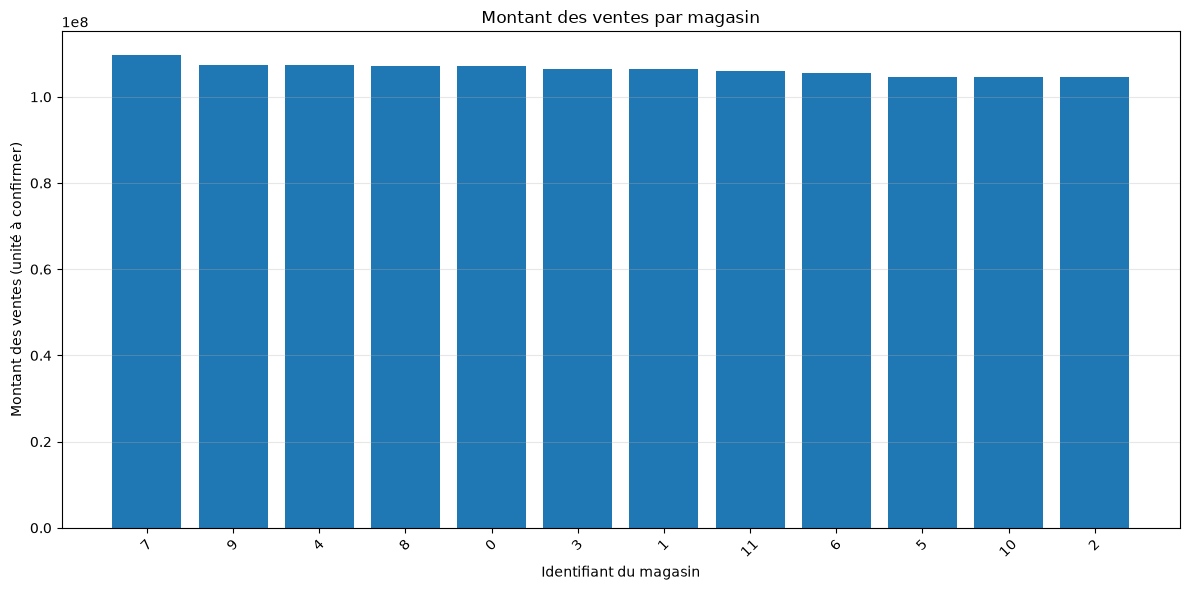

Graphique enregistré : /mnt/d/Dev/M5/Data lake/Cours 1/Retail-project/TP4/UC08/visualisations/ventes_par_magasin.png


In [11]:

import matplotlib.pyplot as plt
from pathlib import Path

racine = Path(
    "/mnt/d/Dev/M5/Data lake/Cours 1/Retail-project"
)

dossier = racine / "TP4/UC08/visualisations"
dossier.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(12, 6))

plt.bar(
    pdf_magasins["magasin_id"].astype(str),
    pdf_magasins["total_ventes"].astype(float)
)

plt.title("Montant des ventes par magasin")
plt.xlabel("Identifiant du magasin")
plt.ylabel("Montant des ventes (unité à confirmer)")
plt.xticks(rotation=45)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    dossier / "ventes_par_magasin.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Graphique enregistré :", dossier / "ventes_par_magasin.png")



### Interprétation — Comparaison des magasins

L'analyse porte sur les 12 magasins présents dans les données
Gold `uc06_finance_magasins`.

Le magasin 7 enregistre le montant de ventes le plus élevé,
avec 109 714 870,06 unités monétaires.

Le magasin 2 présente le montant le plus faible,
avec 104 610 803,14 unités monétaires.

L'écart entre ces magasins est de 5 104 066,92,
soit environ 4,88 % du montant du magasin 2.

Les montants sont relativement proches entre les magasins.

**Limites :**
- Les données sont synthétiques.
- La période d'analyse n'est pas encore documentée.
- L'unité monétaire reste à confirmer.
- Les différences observées ne démontrent pas une meilleure
  performance opérationnelle.



## Analyse métier n°2 — Classement des articles

### Question métier
Quels articles contribuent le plus au montant total des ventes ?

### Source
- Table : `gold/uc06_finance_articles`
- Format : Parquet
- Granularité : un agrégat par article
- Indicateur : `total_ventes`
- Périmètre : 17 820 articles

### Méthode
1. Classer les articles par montant des ventes décroissant.
2. Sélectionner les dix premiers.
3. Calculer leur contribution au total.
4. Produire un graphique en barres horizontales.
5. Interpréter les résultats et leurs limites.

### Limites
L'analyse repose sur les identifiants des articles.
La catégorie, la marque et les autres caractéristiques
produit ne sont pas prises en compte ici.


In [12]:

from pyspark.sql import functions as F

# Classement par montant décroissant
top_articles = (
    gold_articles
    .select(
        "article_id",
        "nombre_lignes",
        "quantite_totale",
        "total_ventes"
    )
    .orderBy(F.desc("total_ventes"))
    .limit(10)
)

print("===== TOP 10 ARTICLES =====")
top_articles.show(10, truncate=False)

# Calcul du total général
total_articles = gold_articles.agg(
    F.sum("total_ventes").alias("total")
).first()["total"]

# Vérification avec les KPI globaux
total_kpi = kpi.first()["montant_ventes"]

assert abs(
    float(total_articles) - float(total_kpi)
) < 0.01

# Contribution du top 10
total_top10 = top_articles.agg(
    F.sum("total_ventes").alias("total")
).first()["total"]

part_top10 = (
    float(total_top10) / float(total_articles) * 100
)

print("\n===== CONTRIBUTION TOP 10 =====")
print("Montant total :", total_articles)
print("Montant top 10 :", total_top10)
print("Contribution (%) :", round(part_top10, 2))
print("Contrôle des montants : OK")

# Conversion d'un petit résultat vers Pandas
pdf_articles = top_articles.toPandas()


===== TOP 10 ARTICLES =====
+----------+-------------+---------------+------------+
|article_id|nombre_lignes|quantite_totale|total_ventes|
+----------+-------------+---------------+------------+
|10000     |9029         |454954         |17132394.87 |
|10003     |8761         |439086         |16546857.98 |
|10001     |8269         |420138         |16042740.21 |
|10002     |7505         |377027         |14232584.38 |
|17502     |1878         |94625          |3665153.84  |
|10579     |1767         |91179          |3642188.14  |
|8601      |1761         |89600          |3593107.69  |
|5618      |1867         |95677          |3511170.04  |
|16513     |1817         |91710          |3503889.39  |
|2651      |1730         |88936          |3503650.60  |
+----------+-------------+---------------+------------+


===== CONTRIBUTION TOP 10 =====
Montant total : 1277224004.61
Montant top 10 : 85373737.14
Contribution (%) : 6.68
Contrôle des montants : OK


/home/honi/environnements/retail-tp3/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Top 10 des articles

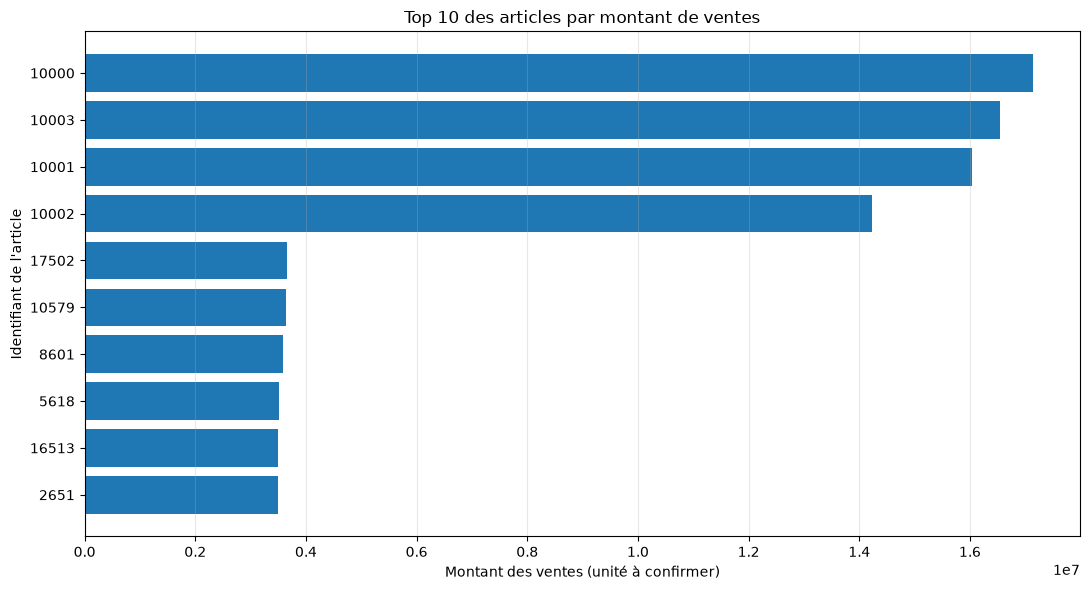

Graphique enregistré : /mnt/d/Dev/M5/Data lake/Cours 1/Retail-project/TP4/UC08/visualisations/top_10_articles.png


In [15]:

import matplotlib.pyplot as plt
from pathlib import Path

racine = Path(
    "/mnt/d/Dev/M5/Data lake/Cours 1/Retail-project"
)

dossier = racine / "TP4/UC08/visualisations"
dossier.mkdir(parents=True, exist_ok=True)

# Ordre croissant pour le graphique horizontal
pdf_graphique = pdf_articles.sort_values(
    "total_ventes", ascending=True
)

plt.figure(figsize=(11, 6))

plt.barh(
    pdf_graphique["article_id"].astype(str),
    pdf_graphique["total_ventes"].astype(float)
)

plt.title("Top 10 des articles par montant de ventes")
plt.xlabel("Montant des ventes (unité à confirmer)")
plt.ylabel("Identifiant de l'article")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    dossier / "top_10_articles.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Graphique enregistré :", dossier / "top_10_articles.png")



### Interprétation — Classement des articles

L'analyse porte sur les 17 820 articles du jeu Gold
`uc06_finance_articles`.

L'article 10000 présente le montant de ventes le plus élevé,
avec 17 132 394,87 unités monétaires.

Il est suivi des articles 10003, 10001 et 10002,
dont les montants sont également nettement supérieurs
à ceux des autres articles du Top 10.

Les dix premiers articles représentent un montant cumulé
de 85 373 737,14, soit 6,68 % du montant total des ventes
(1 277 224 004,61).

Le reste des articles représente environ 93,32 % du total.

### Limites
- Les données TPCx-BB sont synthétiques.
- L'unité monétaire reste à confirmer.
- L'analyse porte uniquement sur les montants de ventes.
- Les catégories, les marges et les caractéristiques
  des articles ne sont pas étudiées ici.
- La période couverte reste à documenter.



Export des résultats analytiques


In [17]:

from pathlib import Path

racine = Path(
    "/mnt/d/Dev/M5/Data lake/Cours 1/Retail-project"
)

dossier_exports = racine / "TP4/UC08/outputs"
dossier_exports.mkdir(parents=True, exist_ok=True)

# Export des KPI
kpi.toPandas().to_csv(
    dossier_exports / "kpi_globaux.csv",
    index=False
)

# Export du classement des magasins
pdf_magasins.to_csv(
    dossier_exports / "ventes_par_magasin.csv",
    index=False
)

# Export du Top 10 des articles
pdf_articles.to_csv(
    dossier_exports / "top_10_articles.csv",
    index=False
)

# Export des statistiques descriptives
statistiques.toPandas().to_csv(
    dossier_exports / "statistiques_descriptives.csv",
    index=False
)

print("===== EXPORTS TERMINÉS =====")

for fichier in sorted(dossier_exports.glob("*.csv")):
    print(fichier.name, "-", fichier.stat().st_size, "octets")


/home/honi/environnements/retail-tp3/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/honi/environnements/retail-tp3/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
[Stage 98:>                                                         (0 + 2) / 2]

===== EXPORTS TERMINÉS =====
kpi_globaux.csv - 139 octets
statistiques_descriptives.csv - 146 octets
top_10_articles.csv - 339 octets
ventes_par_magasin.csv - 404 octets
